# Decoding: Temperatur, Top-k und Top-p (Rechenbeispiel)

**Didaktisches Ziel:** *Das Modell liefert nur eine Wahrscheinlichkeitsverteilung. Welcher Text daraus entsteht, entscheidet die Decoding-Strategie.*

Dieses Notebook knüpft an die Folie **„Softmax-Berechnung aus Logits“** an und verwendet dieselben Zahlen:

1. Softmax für Frankreich / Deutschland / Spanien von Hand nachrechnen
2. **Temperatur** an genau diesen Logits
3. **Top-k** und **Top-p (Nucleus Sampling)** an einem etwas größeren Vokabular
4. Mehrere Generierungsschritte: warum **Greedy** in Schleifen hängen bleiben kann

> Das Grundprinzip von Temperatur und Sampling zeigt auch `next_token_prediction_toy.ipynb`. Hier geht es um die Unterschiede zwischen den Strategien.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # reproduzierbares Sampling
np.set_printoptions(precision=3, suppress=True)

def softmax(z):
    # Numerisch stabile Softmax: Maximum abziehen, damit exp() nicht überläuft.
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max())
    return e / e.sum()

def plot_probs(tokens, p, title, highlight=None):
    x = np.arange(len(tokens))
    colors = ["tab:blue" if highlight is None or highlight[i] else "lightgray" for i in x]
    plt.figure(figsize=(8, 3))
    plt.bar(x, p, color=colors)
    plt.xticks(x, tokens, rotation=20, ha="right")
    plt.ylim(0, 1)
    plt.ylabel("p")
    plt.title(title)
    plt.tight_layout()
    plt.show()

## 1) Das Rechenbeispiel aus dem Skript

Kontextvektor nach Attention: $h = (0.304,\ 0.529,\ 0.603,\ 0.399)$.
Die Zeilen von $W_{out}$ (ohne Bias) für das Mini-Vokabular:

| Token | Zeile in $W_{out}$ |
| :--- | :---: |
| Frankreich | $(1.0,\ 0.5,\ 1.0,\ 0.5)$ |
| Deutschland | $(0.0,\ 1.0,\ 0.0,\ 1.0)$ |
| Spanien | $(1.0,\ 0.0,\ 1.0,\ 0.0)$ |

Logits: $z = W_{out} \cdot h$, danach Softmax.

In [2]:
vocab3 = ["Frankreich", "Deutschland", "Spanien"]
h = np.array([0.304, 0.529, 0.603, 0.399])
W_out = np.array([
    [1.0, 0.5, 1.0, 0.5],   # Frankreich
    [0.0, 1.0, 0.0, 1.0],   # Deutschland
    [1.0, 0.0, 1.0, 0.0],   # Spanien
])

z3 = W_out @ h
e3 = np.exp(z3)
p3 = e3 / e3.sum()

print(f"{'Token':<12} {'Logit z':>8} {'e^z':>7} {'p':>6}")
for t, zi, ei, pi in zip(vocab3, z3, e3, p3):
    print(f"{t:<12} {zi:>8.3f} {ei:>7.2f} {pi:>6.2f}")
print(f"{'Summe':<12} {'':>8} {e3.sum():>7.2f} {p3.sum():>6.2f}")

Token         Logit z     e^z      p
Frankreich      1.371    3.94   0.44
Deutschland     0.928    2.53   0.28
Spanien         0.907    2.48   0.28
Summe                    8.95   1.00


Das ergibt dieselben Werte wie auf der Folie (der exakte Logit ist $1.3715$, die Folie rundet auf $1.372$): Frankreich liegt mit **44 %** vorn, Deutschland und Spanien folgen mit je etwa 28 %.
Die Logits liegen dicht beieinander, deshalb ist die Verteilung recht **flach**. Die Wahl ist für das Modell hier also alles andere als eindeutig.

## 2) Temperatur an den Skript-Logits

$$
p_i(T) = \mathrm{softmax}\!\left(\frac{z_i}{T}\right)
$$

Die Logits werden **vor** der Softmax durch $T$ geteilt:

- $T < 1$: Abstände zwischen den Logits werden größer, die Verteilung wird **spitzer**
- $T > 1$: Abstände schrumpfen, die Verteilung wird **flacher**
- $T \to 0$: entspricht Greedy (immer das Maximum)

**Von Hand für $T = 0.5$:** $z/T = (2.744,\ 1.856,\ 1.814)$, also $e^{z/T} \approx (15.55,\ 6.40,\ 6.14)$ mit Summe $28.09$.
Damit $p \approx (0.55,\ 0.23,\ 0.22)$: Frankreich gewinnt deutlich an Gewicht.

In [3]:
for T in [0.1, 0.5, 1.0, 2.0, 5.0]:
    pT = softmax(z3 / T)
    print(f"T = {T:>4}: " + "  ".join(f"{t} {p:.2f}" for t, p in zip(vocab3, pT)))

T =  0.1: Frankreich 0.98  Deutschland 0.01  Spanien 0.01
T =  0.5: Frankreich 0.55  Deutschland 0.23  Spanien 0.22
T =  1.0: Frankreich 0.44  Deutschland 0.28  Spanien 0.28
T =  2.0: Frankreich 0.39  Deutschland 0.31  Spanien 0.31
T =  5.0: Frankreich 0.35  Deutschland 0.32  Spanien 0.32


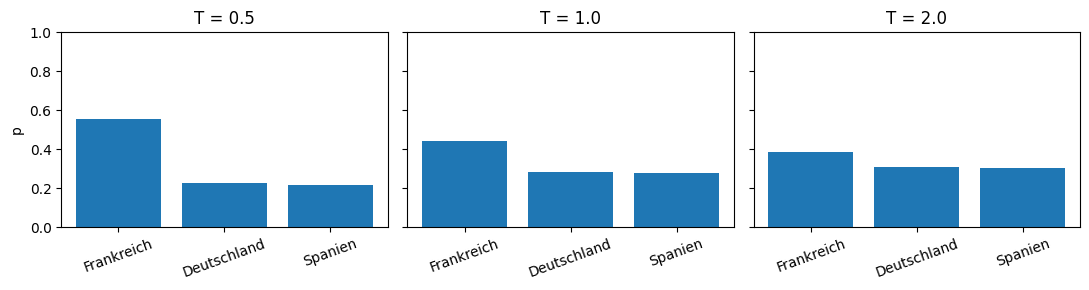

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, T in zip(axes, [0.5, 1.0, 2.0]):
    ax.bar(vocab3, softmax(z3 / T))
    ax.set_title(f"T = {T}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("p")
plt.tight_layout()
plt.show()

## 3) Top-k und Top-p an einem größeren Vokabular

Mit drei Tokens lohnt sich das Abschneiden kaum. Deshalb nehmen wir die Logits der ersten Tabelle auf der Folie (3.2 / 1.7 / 1.2) und ergänzen ein paar weniger passende Tokens.
Satzanfang: *„Paris ist die Hauptstadt von …“*

**Top-k:** Nur die $k$ wahrscheinlichsten Tokens bleiben übrig, dann wird neu normiert.

**Top-p (Nucleus):** Die Tokens werden absteigend sortiert und so lange aufgenommen, bis ihre Summe mindestens $p$ erreicht. Die Anzahl der übrigen Tokens passt sich also der Verteilung an:
ist sich das Modell sicher, bleiben wenige übrig; ist es unsicher, bleiben mehr übrig.

In [5]:
vocab = ["Frankreich", "Deutschland", "Spanien", "Europa", "Italien", "Paris", "und", "Banane"]
logits = np.array([3.2, 1.7, 1.2, 0.6, 0.4, 0.1, -0.8, -2.5])
p = softmax(logits)

for t, pi in zip(vocab, p):
    print(f"{t:<12} {pi:.3f}")

Frankreich   0.641
Deutschland  0.143
Spanien      0.087
Europa       0.048
Italien      0.039
Paris        0.029
und          0.012
Banane       0.002


In [6]:
def top_k_filter(p, k):
    keep = np.zeros_like(p, dtype=bool)
    keep[np.argsort(p)[::-1][:k]] = True
    q = np.where(keep, p, 0.0)
    return q / q.sum(), keep

def top_p_filter(p, top_p):
    order = np.argsort(p)[::-1]
    cum = np.cumsum(p[order])
    # Alle Tokens bis einschließlich dem, mit dem die Schwelle erreicht wird
    n_keep = int(np.searchsorted(cum, top_p) + 1)
    keep = np.zeros_like(p, dtype=bool)
    keep[order[:n_keep]] = True
    q = np.where(keep, p, 0.0)
    return q / q.sum(), keep

order = np.argsort(p)[::-1]
print("Kumulierte Summe (sortiert):")
for t, c in zip(np.array(vocab)[order], np.cumsum(p[order])):
    print(f"  {t:<12} {c:.3f}")

Kumulierte Summe (sortiert):
  Frankreich   0.641
  Deutschland  0.784
  Spanien      0.871
  Europa       0.918
  Italien      0.957
  Paris        0.986
  und          0.998
  Banane       1.000


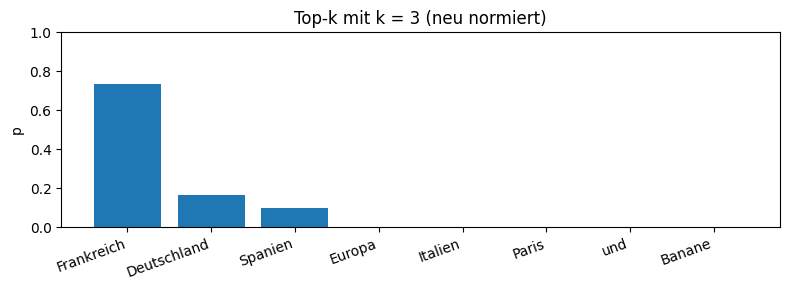

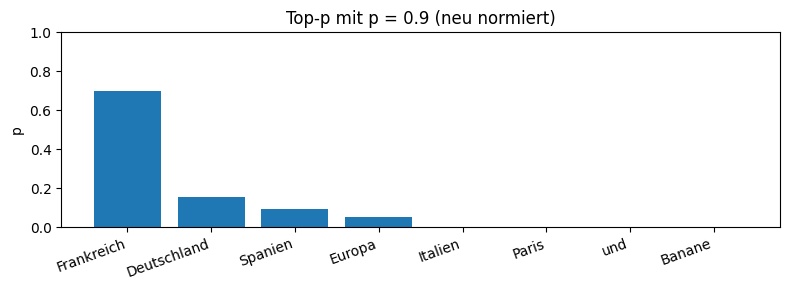

Top-p behält: ['Frankreich', 'Deutschland', 'Spanien', 'Europa']


In [7]:
q_k, keep_k = top_k_filter(p, k=3)
plot_probs(vocab, q_k, "Top-k mit k = 3 (neu normiert)", highlight=keep_k)

q_p, keep_p = top_p_filter(p, top_p=0.9)
plot_probs(vocab, q_p, "Top-p mit p = 0.9 (neu normiert)", highlight=keep_p)
print("Top-p behält:", [t for t, k in zip(vocab, keep_p) if k])

**Warum Top-p oft angenehmer ist als Top-k:** Wir vergleichen eine *sichere* mit einer *unsicheren* Situation.
Top-k behält immer genau $k$ Tokens. Top-p behält bei Sicherheit wenige und bei Unsicherheit viele.

In [8]:
situations = {
    "sicher":   np.array([6.0, 1.0, 0.5, 0.2, 0.0, -0.5, -1.0, -2.0]),
    "unsicher": np.array([1.0, 0.9, 0.8, 0.8, 0.7, 0.6, 0.2, -1.0]),
}
for name, z in situations.items():
    ps = softmax(z)
    _, kk = top_k_filter(ps, 3)
    _, kp = top_p_filter(ps, 0.9)
    print(f"{name:<9} Top-k=3 behält {kk.sum()} Tokens, Top-p=0.9 behält {kp.sum()} Tokens")

sicher    Top-k=3 behält 3 Tokens, Top-p=0.9 behält 1 Tokens
unsicher  Top-k=3 behält 3 Tokens, Top-p=0.9 behält 7 Tokens


## 4) Mehrere Schritte: ein Mini-Sprachmodell

Ein echtes LLM erzeugt Text **Token für Token**: Das gewählte Token wird an den Kontext angehängt und die Vorhersage beginnt von vorn.
Unser Spielzeug-Modell kennt als Kontext nur das **letzte** Token (ein Bigramm-Modell). Die Logits sind von Hand gesetzt.

In [9]:
tokens = ["Die", "Katze", "sieht", "die", "Maus", "schläft", ".", "<EOS>"]
idx = {t: i for i, t in enumerate(tokens)}

# Zeile = aktuelles Token, Spalte = Logit für das nächste Token
L = np.full((len(tokens), len(tokens)), -3.0)
def setze(von, **ziele):
    for t, z in ziele.items():
        L[idx[von], idx[t]] = z

setze("Die",     Katze=2.0, Maus=1.0)
setze("Katze",   sieht=1.5, schläft=1.2, **{".": 0.3})
setze("sieht",   die=2.0, **{".": 0.2})
setze("die",     Katze=1.6, Maus=1.3)
setze("Maus",    schläft=1.0, sieht=0.8, **{".": 0.6})
setze("schläft", **{".": 2.0}, die=-1.0)
setze(".",       **{"<EOS>": 3.0})

def generate(strategy, max_len=14, T=1.0, k=None, top_p=None, rng=rng):
    seq = ["Die"]
    while seq[-1] != "<EOS>" and len(seq) < max_len:
        p = softmax(L[idx[seq[-1]]] / T)
        if strategy == "greedy":
            nxt = int(np.argmax(p))
        else:
            if k is not None:
                p, _ = top_k_filter(p, k)
            if top_p is not None:
                p, _ = top_p_filter(p, top_p)
            nxt = int(rng.choice(len(tokens), p=p))
        seq.append(tokens[nxt])
    return " ".join(seq)

In [10]:
print("Greedy:")
print("  ", generate("greedy"))

Greedy:
   Die Katze sieht die Katze sieht die Katze sieht die Katze sieht die Katze


**Greedy läuft in eine Schleife:** Nach „sieht“ ist „die“ am wahrscheinlichsten, danach „Katze“, danach wieder „sieht“ und so weiter.
Jeder einzelne Schritt ist für sich optimal, der Text als Ganzes aber nicht. Auch echte LLMs zeigen dieses Verhalten bei reinem Greedy-Decoding, deshalb gibt es zusätzlich Sampling und Wiederholungs-Strafen (*repetition penalty*).

In [11]:
print("Sampling, T = 1.0:")
for _ in range(5):
    print("  ", generate("sample", T=1.0))

print("\nSampling, T = 0.3:")
for _ in range(5):
    print("  ", generate("sample", T=0.3))

print("\nSampling, T = 2.0, ohne Filter:")
for _ in range(5):
    print("  ", generate("sample", T=2.0))

print("\nSampling, T = 2.0, mit Top-p = 0.8:")
for _ in range(5):
    print("  ", generate("sample", T=2.0, top_p=0.8))

Sampling, T = 1.0:
   Die Maus schläft . <EOS>
   Die Katze . <EOS>
   Die Maus sieht die Katze . <EOS>
   Die Maus schläft . <EOS>
   Die Katze schläft . <EOS>

Sampling, T = 0.3:
   Die Katze schläft . <EOS>
   Die Katze sieht die Katze sieht die Maus schläft . <EOS>
   Die Katze sieht die Katze sieht die Maus schläft . <EOS>
   Die Katze sieht die Katze sieht die Katze schläft . <EOS>
   Die Katze sieht die Katze sieht die Katze sieht die Katze sieht die Katze

Sampling, T = 2.0, ohne Filter:
   Die Die Katze sieht die Maus sieht Katze sieht die Maus schläft . <EOS>
   Die Katze . Maus Die Katze schläft . Maus schläft die Maus schläft .
   Die Katze schläft schläft Katze sieht <EOS>
   Die schläft . <EOS>
   Die <EOS>

Sampling, T = 2.0, mit Top-p = 0.8:
   Die Maus . <EOS>
   Die Katze sieht . <EOS>
   Die Katze sieht die Katze . <EOS>
   Die Maus schläft . <EOS>
   Die Maus sieht die Katze schläft . <EOS>


**Beobachtung:**

- Bei **niedriger Temperatur** verhält sich Sampling fast wie Greedy und bleibt oft in der Schleife hängen.
- Bei **hoher Temperatur ohne Filter** tauchen auch unsinnige Übergänge auf (z. B. „Die die“), weil Tokens mit Logit −3 plötzlich spürbare Wahrscheinlichkeit bekommen.
- **Hohe Temperatur plus Top-p** liefert Vielfalt, schneidet den unsinnigen Rest der Verteilung aber ab. Diese Kombination ist in der Praxis üblich.

## 5) Aufgaben

1. **Von Hand:** Berechne die Softmax der Skript-Logits für $T = 2$. Prüfe dein Ergebnis mit der Zelle in Abschnitt 2.
2. **Top-p-Grenze:** Ab welchem Wert von `top_p` wird im Beispiel aus Abschnitt 3 auch „Europa“ aufgenommen?
3. **Schleife brechen:** Ändere in `setze("sieht", ...)` einen Logit so, dass Greedy nicht mehr in die Schleife läuft.
4. (Optional) **Repetition Penalty:** Ziehe in `generate` von allen Tokens, die schon in `seq` vorkommen, einen festen Betrag (z. B. 1.0) vom Logit ab. Was passiert bei Greedy?

---

### Take-away
**Das Modell berechnet Wahrscheinlichkeiten, das Decoding macht daraus Text.** Temperatur, Top-k und Top-p sind keine Eigenschaften des Modells, sondern Einstellungen bei der Generierung.